# Análisis exploratorio de datos (EDA)

**Proyecto de Redes Neuronales 2026-2 - Universidad del Valle - Entrega 1**

**Integrantes:**
- Johan Andrés Ceballos Tabárez (202372229)
- Juan Sebastián Rodas Ramírez (202359681)
- David Urrego Martinez (2240407)

In [1]:
import os
os.chdir("..")  # sube a la raíz del proyecto para que data/ funcione
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/train.csv")
os.makedirs("figuras", exist_ok=True)
print(df.shape)
df.head()

(10116, 2)


,text,airline_sentiment
0,@JetBlue I lost a day at the airport and off m...,negative
1,"@USAirways please help! No bags, no way to get...",negative
2,@JetBlue be flying soon to NYC on your airline...,positive
3,@SouthwestAir iPhone app now has passbook supp...,positive
4,@SouthwestAir I wish I would've known so I cou...,negative


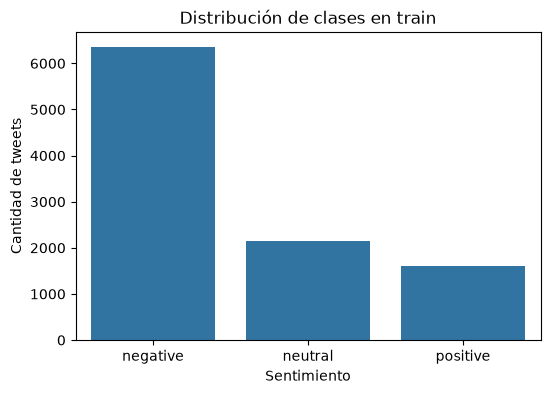

airline_sentiment
negative    0.628806
neutral     0.212238
positive    0.158956
Name: proportion, dtype: float64


In [2]:
orden = ["negative", "neutral", "positive"]
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="airline_sentiment", order=orden)
plt.title("Distribución de clases en train")
plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de tweets")
plt.savefig("figuras/clases.png", dpi=150, bbox_inches="tight")
plt.show()
print(df["airline_sentiment"].value_counts(normalize=True))

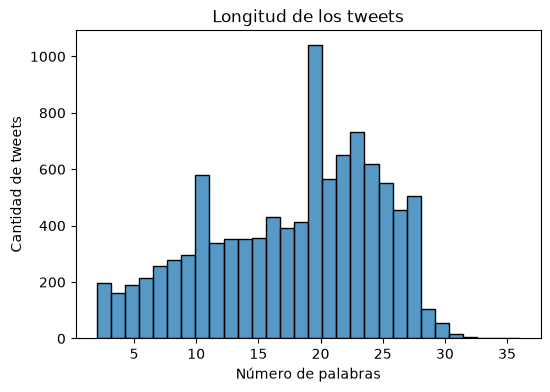

count    10116.000000
mean        17.721530
std          6.833176
min          2.000000
25%         13.000000
50%         19.000000
75%         23.000000
max         36.000000
Name: n_palabras, dtype: float64


In [3]:
df["n_palabras"] = df["text"].str.split().str.len()
plt.figure(figsize=(6, 4))
sns.histplot(df["n_palabras"], bins=30)
plt.title("Longitud de los tweets")
plt.xlabel("Número de palabras")
plt.ylabel("Cantidad de tweets")
plt.savefig("figuras/longitud.png", dpi=150, bbox_inches="tight")
plt.show()
print(df["n_palabras"].describe())

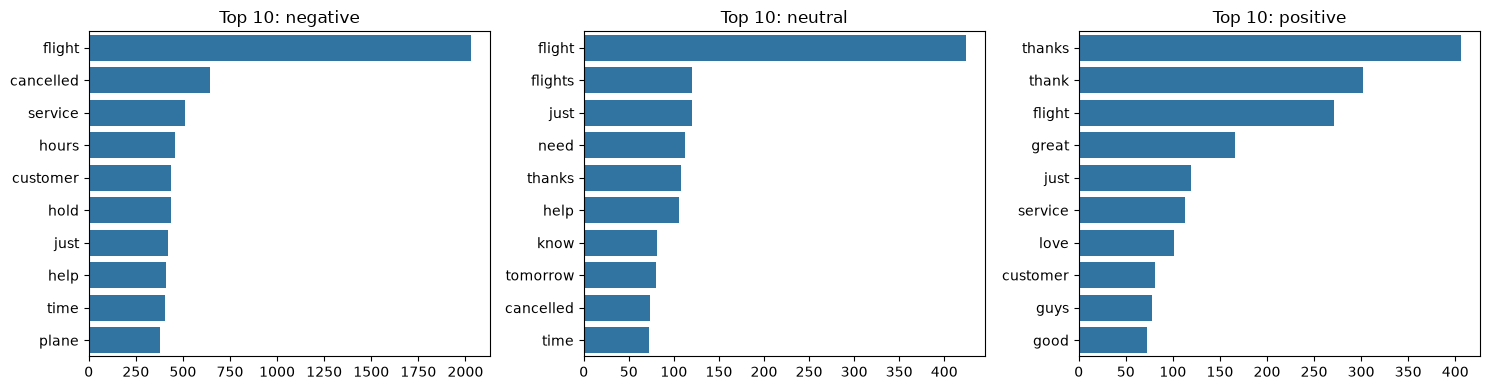

In [4]:
from collections import Counter
from src.preprocess import limpiar
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

df["clean"] = df["text"].apply(limpiar)
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, clase in zip(ejes, orden):
    palabras = " ".join(df[df["airline_sentiment"] == clase]["clean"]).split()
    palabras = [p for p in palabras if p not in ENGLISH_STOP_WORDS and len(p) > 2]
    top = Counter(palabras).most_common(10)
    sns.barplot(x=[c for _, c in top], y=[p for p, _ in top], ax=ax)
    ax.set_title(f"Top 10: {clase}")
plt.tight_layout()
plt.savefig("figuras/top_palabras.png", dpi=150, bbox_inches="tight")
plt.show()